# Exploratory Data Analysis (EDA)

In [6]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

project_dir = Path.cwd().parent
processed_dir = project_dir / "data" / "processed"
fig_dir = project_dir / "reports" / "figures"
table_dir = project_dir / "reports" / "tables"
fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

# continuous response for the regression part: "ppa" or "yardsGained"
REG_TARGET = "ppa"
CORR_THRESHOLD = 0.80 
 # drop features missing more than this share of values
MAX_MISSING = 0.30
MANUAL_KEEP = []
# Engineered flags (thresholds of a raw feature) and sec_left_game (fully determined by period + sec_left_half)
# are dropped FIRST when they are redundant with something else, so the raw football features survive.
PREFER_DROP = ["red_zone", "goal_to_go", "short_yardage", "long_yardage",
               "two_minute", "trailing_late", "sec_left_game"]
SAVE_FIGS = True

CLASS_COLORS = {"Run": "#E69F00", "Pass": "#0072B2"}
TEAM_COLORS = {"Georgia": "#D55E00", "Indiana": "#009E73"}
NEUTRAL = "#8C96A8"

def savefig(fig, name):
    if SAVE_FIGS:
        fig.savefig(fig_dir / f"{name}.png", dpi=150, bbox_inches="tight")

def make_grid(n, ncols=4, w=3.6, h=2.8):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * w, nrows * h))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.set_visible(False)
    return fig, axes

final = pd.read_csv(processed_dir / "model_df.csv")
with open(processed_dir / "feature_lists.json") as f:
    fl = json.load(f)

cat_f, num_f, bin_f = fl["categorical"], fl["numeric"], fl["binary"]
feature_cols = cat_f + num_f + bin_f
missing_cols = [c for c in feature_cols + fl["targets"] + ["split", "requested_team", "gameId"] if c not in final.columns]
assert not missing_cols, f"columns missing from model_df.csv: {missing_cols}"

eda = final[final["split"] == "train"].copy()
eda["play_call"] = np.where(eda["is_pass"] == 1, "Pass", "Run")
print(f"EDA uses {len(eda)} training plays from {eda['gameId'].nunique()} games "
      f"(the other {len(final) - len(eda)} plays are held out as test)")
print(f"{len(feature_cols)} features: {len(cat_f)} categorical, {len(num_f)} numeric, {len(bin_f)} binary")

EDA uses 1395 training plays from 20 games (the other 378 plays are held out as test)
25 features: 2 categorical, 11 numeric, 12 binary


## Two datasets and the Null Model

,games,plays,pass_rate,avg_distance,avg_yards_to_goal,avg_score_diff,mean_ppa,mean_yards
requested_team,,,,,,,,
Georgia,10,709,0.443,8.186,48.801,4.742,0.215,6.141
Indiana,10,686,0.418,7.910,45.832,14.857,0.353,7.423



NullModel, classification: always predict Run -> accuracy 0.569 on the training plays
NullModel, regression: always predict the mean ppa = 0.283 (R^2 = 0 by definition)


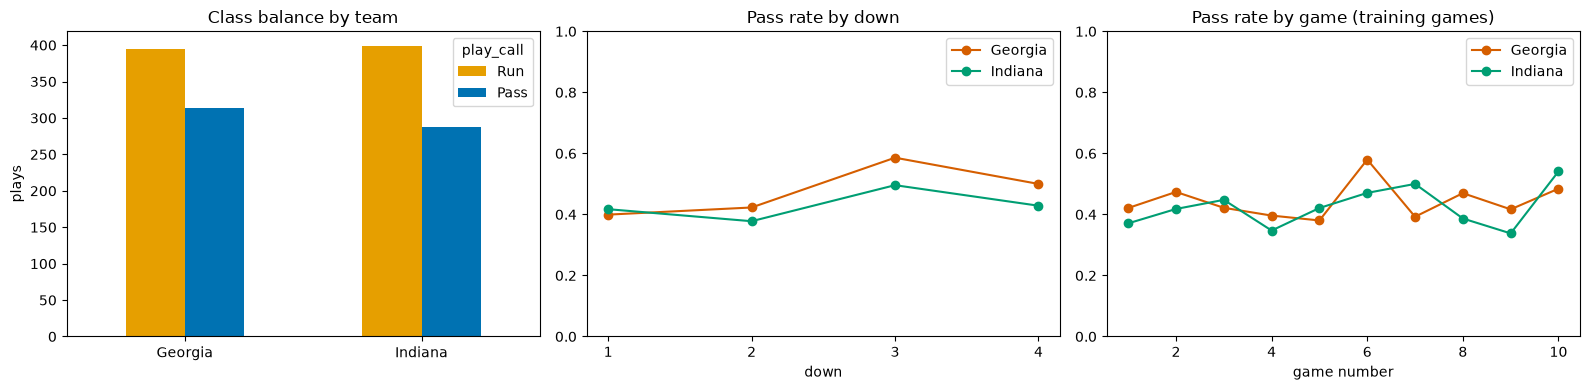

In [7]:
team_table = eda.groupby("requested_team").agg(
    games=("gameId", "nunique"),
    plays=("is_pass", "size"),
    pass_rate=("is_pass", "mean"),
    avg_distance=("distance", "mean"),
    avg_yards_to_goal=("yardsToGoal", "mean"),
    avg_score_diff=("score_diff", "mean"),
    mean_ppa=("ppa", "mean"),
    mean_yards=("yardsGained", "mean"),
).round(3)
display(team_table)
team_table.to_csv(table_dir / "01_team_comparison.csv")

# NullModels (what every real model has to beat)
pass_rate = eda["is_pass"].mean()
print(f"\nNullModel, classification: always predict {'Run' if pass_rate < .5 else 'Pass'} "
      f"-> accuracy {max(pass_rate, 1 - pass_rate):.3f} on the training plays")
print(f"NullModel, regression: always predict the mean {REG_TARGET} = {eda[REG_TARGET].mean():.3f} (R^2 = 0 by definition)")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

ct = pd.crosstab(eda["requested_team"], eda["play_call"])[["Run", "Pass"]]
ct.plot(kind="bar", ax=axes[0], rot=0, color=[CLASS_COLORS["Run"], CLASS_COLORS["Pass"]])
axes[0].set_title("Class balance by team"); axes[0].set_xlabel(""); axes[0].set_ylabel("plays")

for team, sub in eda.groupby("requested_team"):
    by_down = sub.groupby("down")["is_pass"].mean()
    axes[1].plot(by_down.index, by_down.values, marker="o", color=TEAM_COLORS[team], label=team)
axes[1].set_ylim(0, 1); axes[1].set_xticks([1, 2, 3, 4])
axes[1].set_title("Pass rate by down"); axes[1].set_xlabel("down"); axes[1].legend()

for team, sub in eda.groupby("requested_team"):
    by_game = sub.groupby("game_num")["is_pass"].mean()
    axes[2].plot(by_game.index, by_game.values, marker="o", color=TEAM_COLORS[team], label=team)
axes[2].set_ylim(0, 1)
axes[2].set_title("Pass rate by game (training games)"); axes[2].set_xlabel("game number"); axes[2].legend()

fig.tight_layout(); savefig(fig, "01_overview_teams"); plt.show()

## Feature Audit

In [8]:
types = {**{c: "categorical" for c in cat_f}, **{c: "numeric" for c in num_f}, **{c: "binary" for c in bin_f}}
audit = pd.DataFrame({
    "type": pd.Series(types),
    "n_unique": eda[feature_cols].nunique(),
    "std": eda[feature_cols].std().round(3),
    "pct_missing": (eda[feature_cols].isna().mean() * 100).round(1),
}).loc[feature_cols]

zero_var = audit.index[audit["n_unique"] <= 1].tolist()
high_missing = audit.index[audit["pct_missing"] / 100 > MAX_MISSING].tolist()
print("Zero-variance features:", zero_var or "none")
print(f"Features missing more than {MAX_MISSING:.0%}:", high_missing or "none")
print("\nMissing values that remain are first-play-of-game history and each team's first game;")
print("they are imputed inside the modeling pipeline (fit on training data only).")

audit.to_csv(table_dir / "02_feature_audit.csv")
display(audit.sort_values("pct_missing", ascending=False))

Zero-variance features: none
Features missing more than 30%: none

Missing values that remain are first-play-of-game history and each team's first game;
they are imputed inside the modeling pipeline (fit on training data only).


,type,n_unique,std,pct_missing
team_prior_pass_rate_down,numeric,61,0.068,11.8
team_prior_pass_rate,numeric,18,0.021,11.8
prev_call_3,binary,2,0.496,4.3
prev_call_2,binary,2,0.496,2.9
prev_call_1,binary,2,0.496,1.4
prev_yards,numeric,63,9.227,1.4
pass_rate_last5,numeric,11,0.245,1.4
pass_rate_game_so_far,numeric,419,0.129,1.4
yardsToGoal,numeric,99,25.175,0.0
short_yardage,binary,2,0.307,0.0


## Histograms

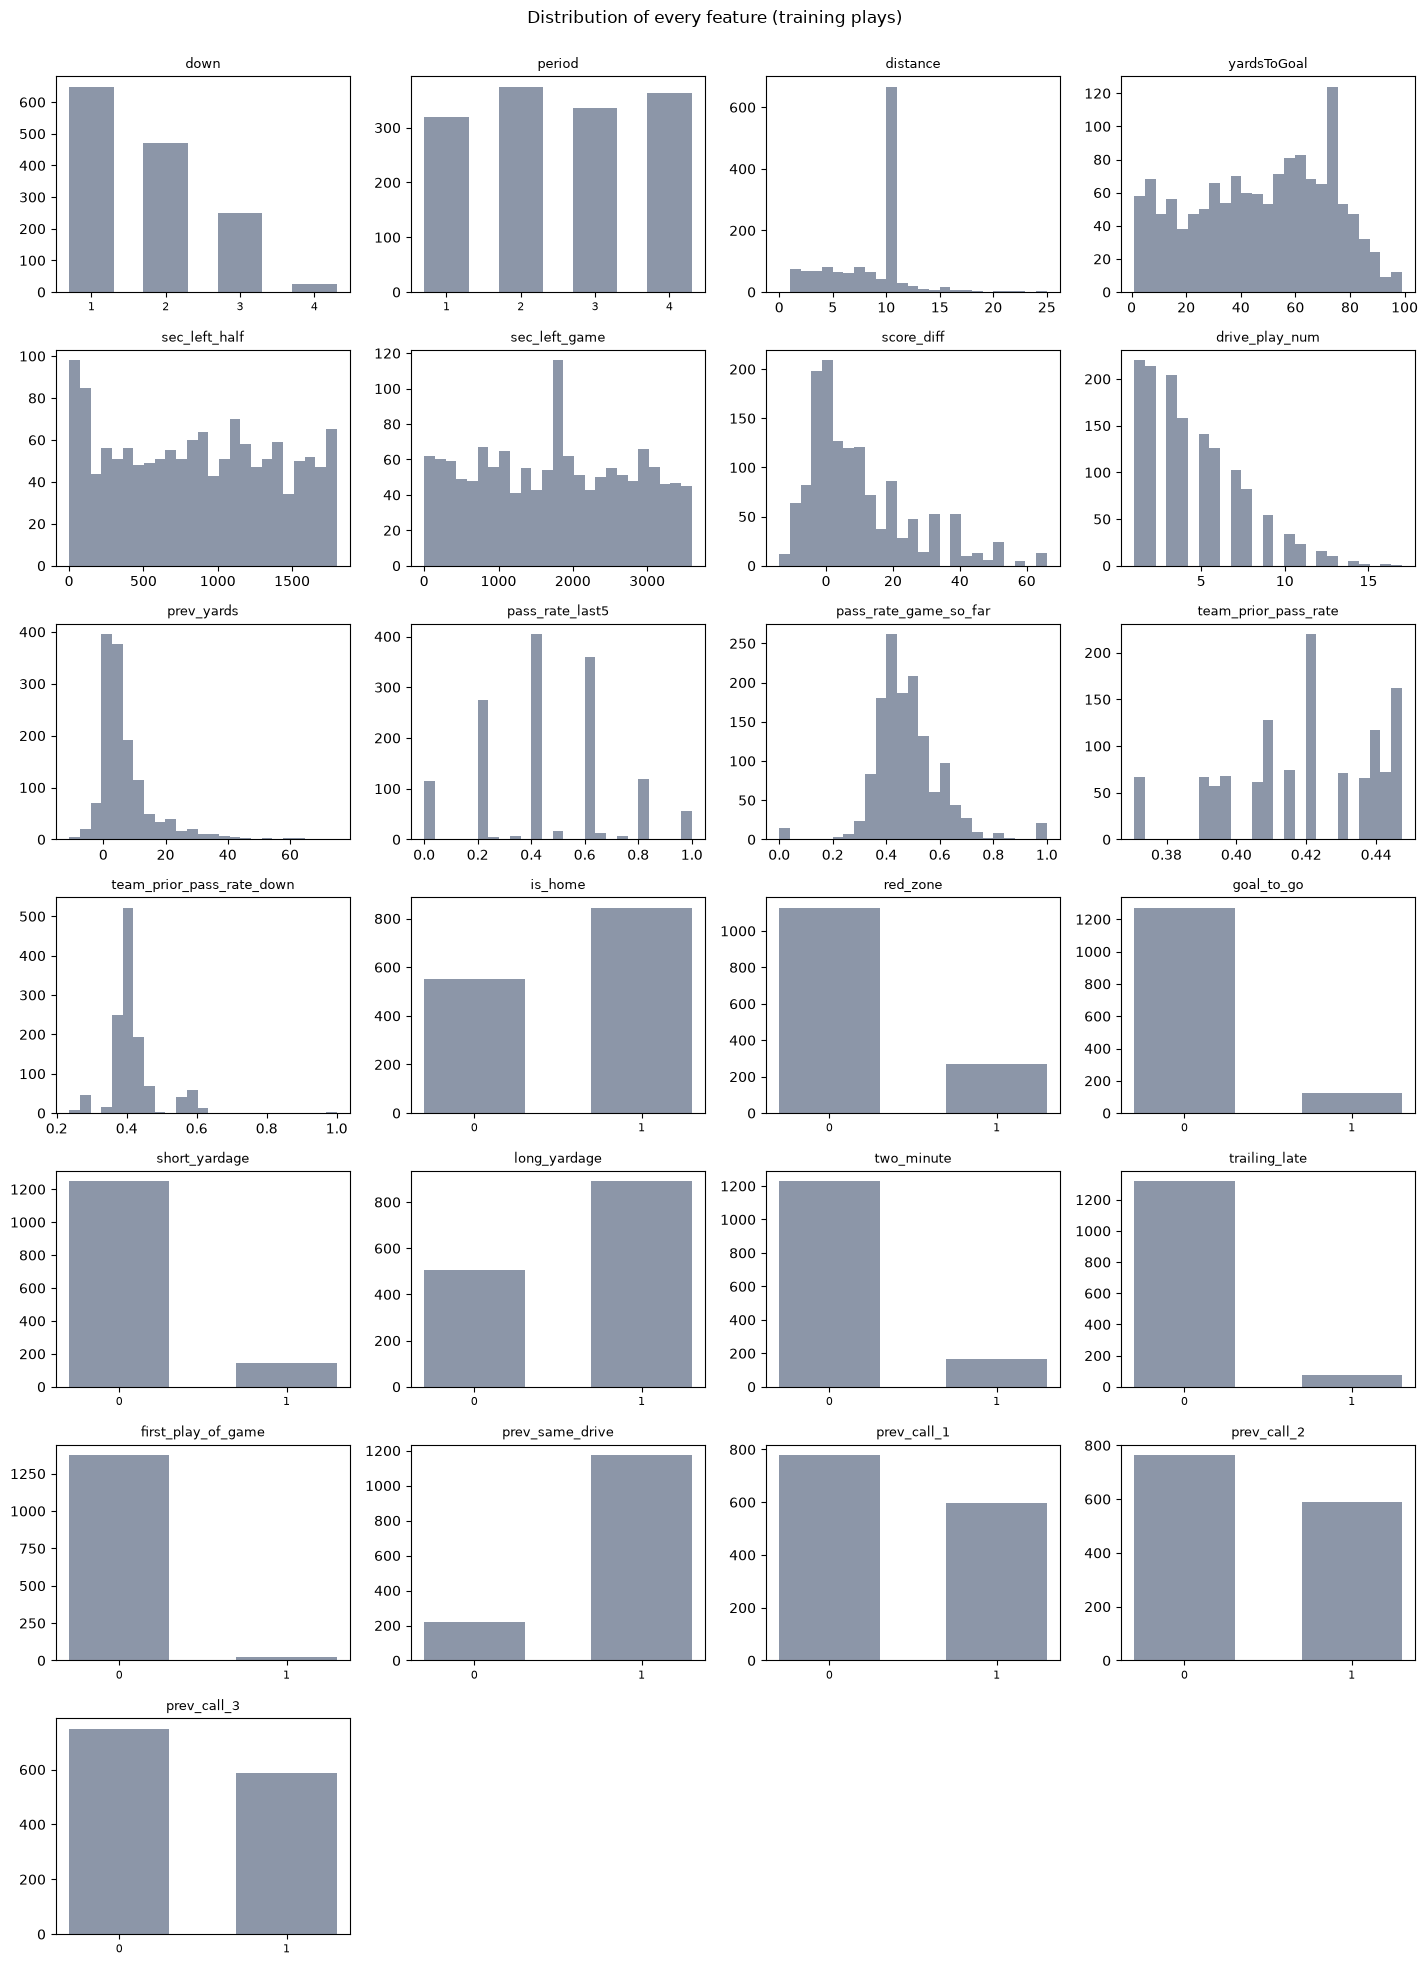

In [9]:
fig, axes = make_grid(len(feature_cols))
for ax, f in zip(axes, feature_cols):
    s = eda[f].dropna()
    if s.nunique() <= 8:
        vc = s.value_counts().sort_index()
        ax.bar(vc.index.astype(float), vc.values, color=NEUTRAL, width=0.6)
        ax.set_xticks(vc.index.astype(float))
        ax.set_xticklabels([f"{v:g}" for v in vc.index], fontsize=8)
    else:
        ax.hist(s, bins=25, color=NEUTRAL)
    ax.set_title(f, fontsize=9)
fig.suptitle("Distribution of every feature (training plays)", y=1.0)
fig.tight_layout(); savefig(fig, "03_histograms_features"); plt.show()

## Box Plots and Outliers

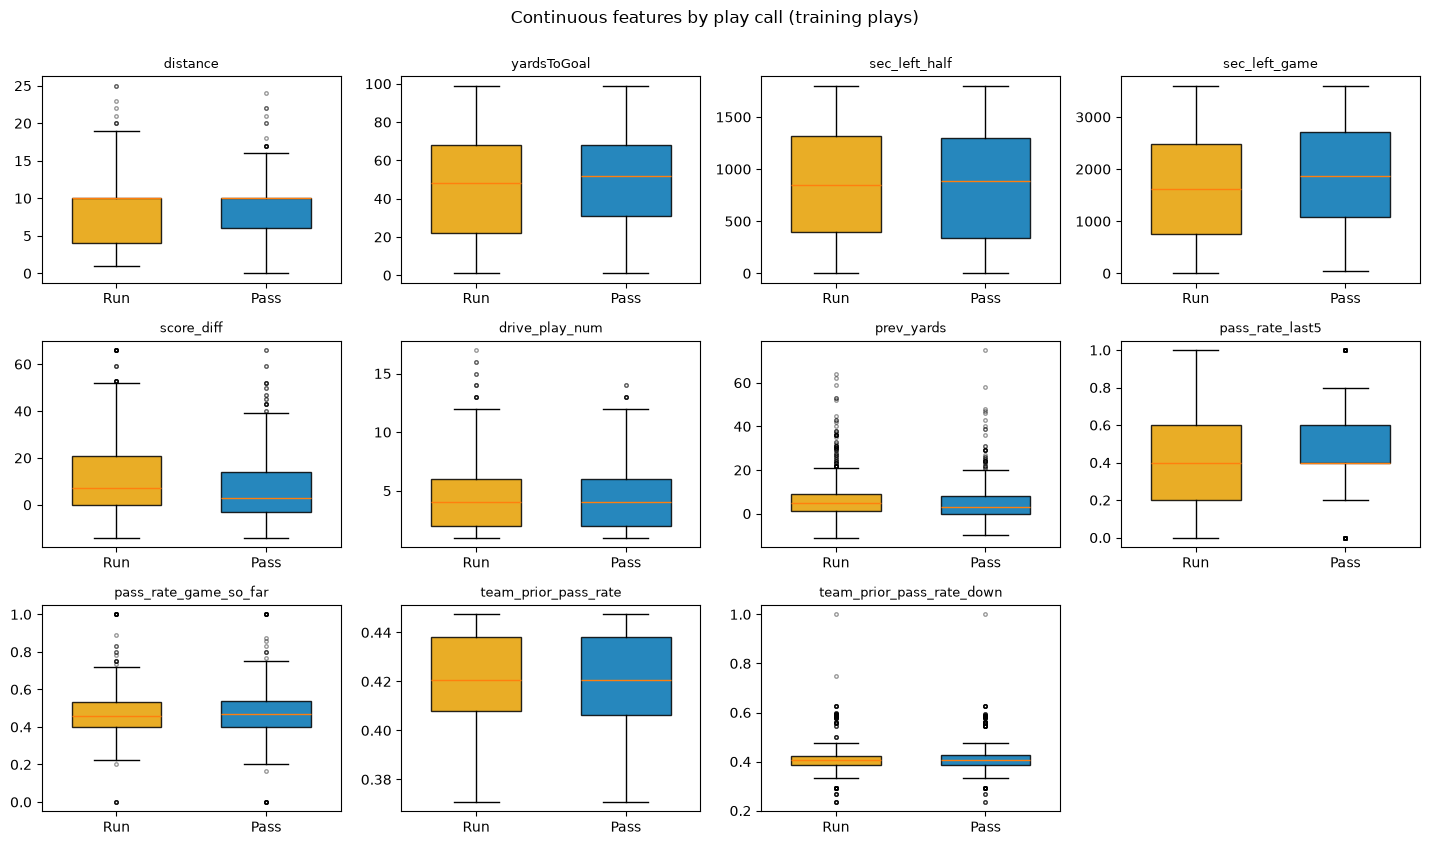

,n,min,max,outside_1.5_IQR,outside_3_IQR,pct_outside_1.5_IQR
distance,1395.0,0.000000,25.000000,17.0,0.0,1.2
yardsToGoal,1395.0,1.000000,99.000000,0.0,0.0,0.0
sec_left_half,1395.0,0.000000,1800.000000,0.0,0.0,0.0
sec_left_game,1395.0,0.000000,3600.000000,0.0,0.0,0.0
score_diff,1395.0,-14.000000,66.000000,42.0,0.0,3.0
drive_play_num,1395.0,1.000000,17.000000,20.0,0.0,1.4
prev_yards,1375.0,-11.000000,75.000000,98.0,33.0,7.1
pass_rate_last5,1375.0,0.000000,1.000000,0.0,0.0,0.0
pass_rate_game_so_far,1375.0,0.000000,1.000000,57.0,21.0,4.1
team_prior_pass_rate,1230.0,0.370787,0.447368,0.0,0.0,0.0


In [10]:
cont = [f for f in num_f if eda[f].nunique() > 8]

fig, axes = make_grid(len(cont))
for ax, f in zip(axes, cont):
    data = [eda.loc[eda["is_pass"] == 0, f].dropna(), eda.loc[eda["is_pass"] == 1, f].dropna()]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6,
                    flierprops=dict(marker="o", markersize=2.5, alpha=0.4))
    for patch, c in zip(bp["boxes"], [CLASS_COLORS["Run"], CLASS_COLORS["Pass"]]):
        patch.set_facecolor(c); patch.set_alpha(0.85)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["Run", "Pass"])
    ax.set_title(f, fontsize=9)
fig.suptitle("Continuous features by play call (training plays)", y=1.0)
fig.tight_layout(); savefig(fig, "04_boxplots_by_play_call"); plt.show()

def iqr_summary(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return pd.Series({
        "n": len(s), "min": s.min(), "max": s.max(),
        "outside_1.5_IQR": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
        "outside_3_IQR": int(((s < q1 - 3 * iqr) | (s > q3 + 3 * iqr)).sum()),
    })

outliers = pd.DataFrame({c: iqr_summary(eda[c]) for c in cont + ["yardsGained", "ppa"]}).T
outliers["pct_outside_1.5_IQR"] = (outliers["outside_1.5_IQR"] / outliers["n"] * 100).round(1)
outliers.to_csv(table_dir / "04_outliers_iqr.csv")
display(outliers)

## Outlier decisions

We detected outliers using the 1.5 IQR rule on the training plays. 

We kept real plays. The large values in `yardsGained` (up to 75 yards),
`ppa` (-7.2 to 6.6), `prev_yards` and `score_diff` (up to +66) are real
football events: long runs and passes, turnovers, and blowout games. They are
not measurement errors, so removing them would delete real situations a
play-caller faces. For the regression models I will report results on the
raw target and, as a robustness check, on the target capped at its 1st and
99th percentiles. The history features
`pass_rate_game_so_far` and `team_prior_pass_rate_down` show extreme values
because they are computed from few earlier plays (early in a game, or in a
team's first games). These are not errors, but they are noisy.

Dropped data errors. `offenseTimeouts` and `defenseTimeouts` contain
impossible values: offensive timeouts range from -7 to 3 (173 of 1,773
plays, 9.8%, are negative) and defensive from -3 to 3 (12 plays, 0.7%).
A team has 0-3 timeouts per half, so the source appears to be a counter
that is decremented without being reset. Because the non-negative values
come from the same counter, I could not trust them either, and I removed
both features instead of clipping. Timeouts have little effect on
pass/run decisions outside the end of a half, which `sec_left_half` and
`two_minute` already capture.

## Pass/Run classification response

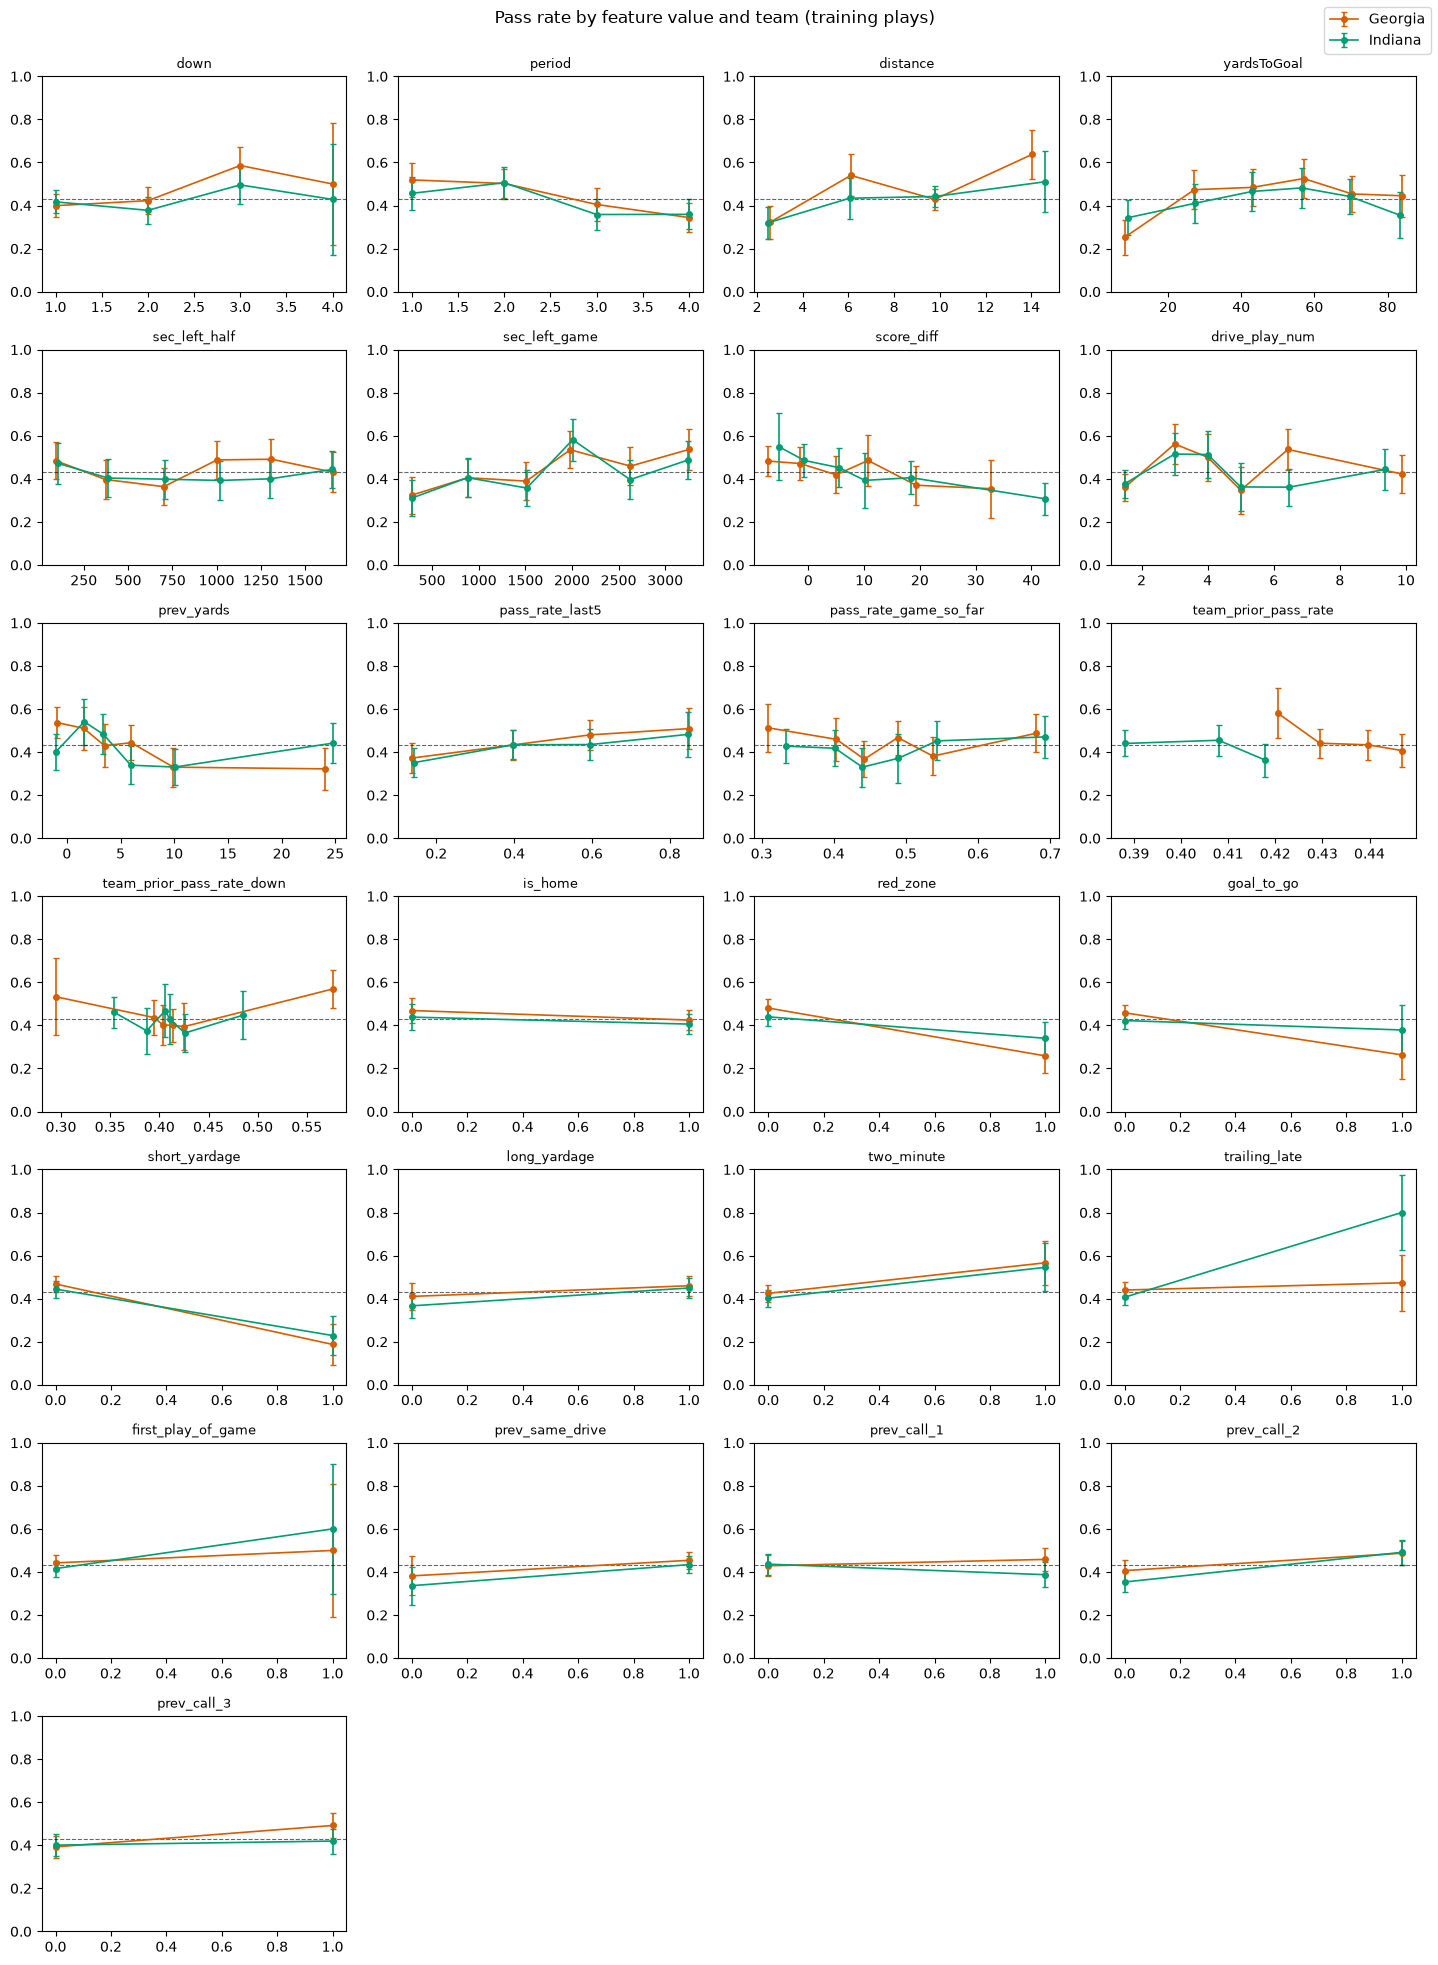

In [11]:
def rate_table(f, df=eda, max_levels=8, q=6):
    d = df[[f, "is_pass", "requested_team"]].dropna().copy()
    if d[f].nunique() <= max_levels:
        d["bin"] = d[f]
    else:
        d["bin"] = pd.qcut(d[f], q=q, duplicates="drop")
    out = (d.groupby(["requested_team", "bin"], observed=True)
             .agg(rate=("is_pass", "mean"), n=("is_pass", "size"), x=(f, "mean"))
             .reset_index())
    out["se"] = np.sqrt(out["rate"] * (1 - out["rate"]) / out["n"])
    return out

fig, axes = make_grid(len(feature_cols))
for ax, f in zip(axes, feature_cols):
    if eda[f].nunique() < 2:
        ax.set_visible(False)
        continue
    out = rate_table(f)
    out = out[out["n"] >= 10]
    for team, sub in out.groupby("requested_team"):
        ax.errorbar(sub["x"], sub["rate"], yerr=1.96 * sub["se"], marker="o", ms=4, lw=1.2,
                    capsize=2, color=TEAM_COLORS[team], label=team)
    ax.axhline(eda["is_pass"].mean(), color="k", ls="--", lw=0.8, alpha=0.6)
    ax.set_ylim(0, 1); ax.set_title(f, fontsize=9)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right")
fig.suptitle("Pass rate by feature value and team (training plays)", y=1.0)
fig.tight_layout(); savefig(fig, "05_pass_rate_by_feature"); plt.show()

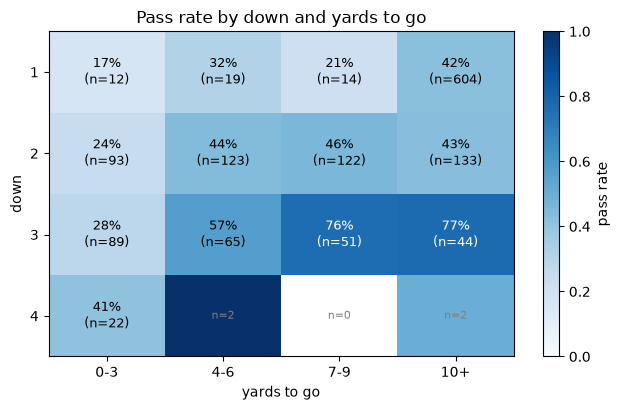

In [12]:
d = eda.copy()
d["dist_bin"] = pd.cut(d["distance"], [-1, 3, 6, 9, 100], labels=["0-3", "4-6", "7-9", "10+"])
rate = d.pivot_table(index="down", columns="dist_bin", values="is_pass", aggfunc="mean", observed=False)
cnt = d.pivot_table(index="down", columns="dist_bin", values="is_pass", aggfunc="size", observed=False).fillna(0)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
im = ax.imshow(rate.values, vmin=0, vmax=1, cmap="Blues", aspect="auto")
ax.set_xticks(range(rate.shape[1])); ax.set_xticklabels(rate.columns)
ax.set_yticks(range(rate.shape[0])); ax.set_yticklabels(rate.index)
ax.set_xlabel("yards to go"); ax.set_ylabel("down"); ax.grid(False)
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        r, n = rate.values[i, j], int(cnt.values[i, j])
        if n < 10 or np.isnan(r):
            ax.text(j, i, f"n={n}", ha="center", va="center", fontsize=8, color="gray")
        else:
            ax.text(j, i, f"{r:.0%}\n(n={n})", ha="center", va="center", fontsize=9,
                    color="white" if r > 0.6 else "black")
ax.set_title("Pass rate by down and yards to go")
fig.colorbar(im, ax=ax, label="pass rate")
fig.tight_layout(); savefig(fig, "05_pass_rate_down_by_distance"); plt.show()

,auc,strength,higher_means,pearson_r,n
feature,,,,,
period,0.432,0.568,Run,-0.121,1395
sec_left_game,0.565,0.565,Pass,0.111,1395
score_diff,0.435,0.565,Run,-0.123,1395
prev_yards,0.442,0.558,Run,-0.078,1375
prev_call_2,0.555,0.555,Pass,0.110,1355
distance,0.552,0.552,Pass,0.105,1395
pass_rate_last5,0.551,0.551,Pass,0.091,1375
red_zone,0.450,0.550,Run,-0.125,1395
short_yardage,0.453,0.547,Run,-0.152,1395


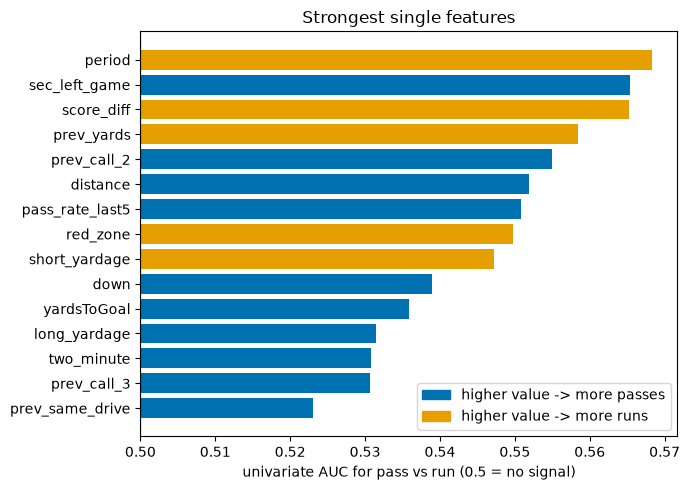

In [13]:
def uni_auc(x, y):
    d = pd.DataFrame({"x": x, "y": y}).dropna()
    n1, n0 = int((d["y"] == 1).sum()), int((d["y"] == 0).sum())
    if n1 == 0 or n0 == 0 or d["x"].nunique() < 2:
        return np.nan
    ranks = stats.rankdata(d["x"])
    return (ranks[d["y"].values == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

rows = []
for f in feature_cols:
    auc = uni_auc(eda[f], eda["is_pass"])
    rows.append(dict(feature=f, auc=auc, strength=abs(auc - 0.5) + 0.5 if pd.notna(auc) else np.nan,
                     higher_means="Pass" if auc > 0.5 else "Run",
                     pearson_r=eda[f].corr(eda["is_pass"]) if eda[f].nunique() > 1 else np.nan,
                     n=int(eda[f].notna().sum())))
uni = pd.DataFrame(rows).set_index("feature").sort_values("strength", ascending=False)
uni.round(3).to_csv(table_dir / "05_univariate_auc_pass_vs_run.csv")
display(uni.round(3).head(15))

top = uni.dropna().head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top["strength"] - 0.5, left=0.5,
        color=[CLASS_COLORS[h] for h in top["higher_means"]])
ax.axvline(0.5, color="k", lw=0.8)
ax.set_xlabel("univariate AUC for pass vs run (0.5 = no signal)")
ax.set_title("Strongest single features")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=CLASS_COLORS["Pass"], label="higher value -> more passes"),
                   Patch(color=CLASS_COLORS["Run"], label="higher value -> more runs")], loc="lower right")
fig.tight_layout(); savefig(fig, "05_univariate_auc"); plt.show()

## PPA/yards regression response

Regression response: ppa  (1394 training plays with a value; 1 missing and excluded here)
1st / 99th percentile of ppa: -4.24 / 3.62


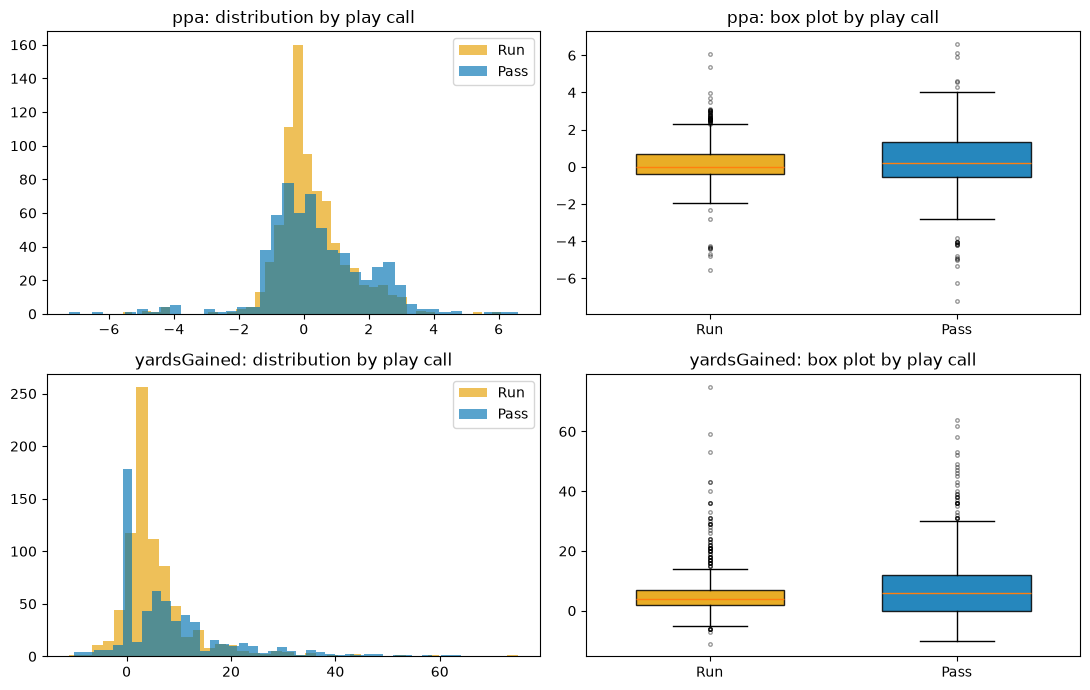

In [14]:
reg = eda.dropna(subset=[REG_TARGET]).copy()
print(f"Regression response: {REG_TARGET}  ({len(reg)} training plays with a value; {len(eda) - len(reg)} missing and excluded here)")
print(f"1st / 99th percentile of {REG_TARGET}: {reg[REG_TARGET].quantile(.01):.2f} / {reg[REG_TARGET].quantile(.99):.2f}")

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, t in enumerate(["ppa", "yardsGained"]):
    s = eda.dropna(subset=[t])
    for cls in ["Run", "Pass"]:
        axes[row, 0].hist(s.loc[s["play_call"] == cls, t], bins=40, alpha=0.65,
                          color=CLASS_COLORS[cls], label=cls)
    axes[row, 0].set_title(f"{t}: distribution by play call"); axes[row, 0].legend()
    bp = axes[row, 1].boxplot([s.loc[s["play_call"] == c, t] for c in ["Run", "Pass"]],
                              patch_artist=True, widths=0.6,
                              flierprops=dict(marker="o", markersize=2.5, alpha=0.4))
    for patch, c in zip(bp["boxes"], [CLASS_COLORS["Run"], CLASS_COLORS["Pass"]]):
        patch.set_facecolor(c); patch.set_alpha(0.85)
    axes[row, 1].set_xticks([1, 2]); axes[row, 1].set_xticklabels(["Run", "Pass"])
    axes[row, 1].set_title(f"{t}: box plot by play call")
fig.tight_layout(); savefig(fig, "06_regression_targets"); plt.show()

In [15]:
# Simple linear regression y = b0 + b1*x for each feature, plus a quadratic check
rows = []
for f in feature_cols:
    d = reg[[f, REG_TARGET]].dropna()
    if d[f].nunique() < 2:
        continue
    lr = stats.linregress(d[f], d[REG_TARGET])
    r2_quad = np.nan
    if d[f].nunique() > 2:
        z = (d[f] - d[f].mean()) / d[f].std()
        pred = np.polyval(np.polyfit(z, d[REG_TARGET], 2), z)
        r2_quad = 1 - ((d[REG_TARGET] - pred) ** 2).sum() / ((d[REG_TARGET] - d[REG_TARGET].mean()) ** 2).sum()
    rows.append(dict(feature=f, n=len(d), b0=lr.intercept, b1=lr.slope, r=lr.rvalue,
                     R2=lr.rvalue ** 2, p_value=lr.pvalue, R2_quadratic=r2_quad))
simple_reg = pd.DataFrame(rows).set_index("feature").sort_values("R2", ascending=False)
simple_reg["R2_gain_from_quadratic"] = simple_reg["R2_quadratic"] - simple_reg["R2"]
simple_reg.to_csv(table_dir / "06_simple_regression_per_feature.csv")
display(simple_reg.round(4).head(15))

print(f"\nBest single-feature R^2 for {REG_TARGET}: {simple_reg['R2'].max():.4f} ({simple_reg['R2'].idxmax()})")
print("A NullModel has R^2 = 0, so single features that explain this little leave little room for any model.")
curved = simple_reg[simple_reg["R2_gain_from_quadratic"] > 0.01]
print("Features where a quadratic term adds > 0.01 R^2 (candidates for the transformed-regression model):",
      curved.index.tolist() or "none")

,n,b0,b1,r,R2,p_value,R2_quadratic,R2_gain_from_quadratic
feature,,,,,,,,
down,1394,0.0186,0.1509,0.0908,0.0082,0.0007,0.0095,0.0013
long_yardage,1394,0.4132,-0.2045,-0.0730,0.0053,0.0064,NaN,NaN
is_home,1394,0.1655,0.1935,0.0702,0.0049,0.0087,NaN,NaN
prev_yards,1374,0.3472,-0.0094,-0.0642,0.0041,0.0173,0.0048,0.0007
score_diff,1394,0.2298,0.0054,0.0638,0.0041,0.0173,0.0044,0.0004
team_prior_pass_rate,1229,1.9761,-4.0197,-0.0620,0.0038,0.0297,0.0045,0.0007
red_zone,1394,0.2435,0.2053,0.0599,0.0036,0.0253,NaN,NaN
drive_play_num,1394,0.1855,0.0216,0.0476,0.0023,0.0754,0.0027,0.0005
goal_to_go,1394,0.2642,0.2085,0.0439,0.0019,0.1010,NaN,NaN



Best single-feature R^2 for ppa: 0.0082 (down)
A NullModel has R^2 = 0, so single features that explain this little leave little room for any model.
Features where a quadratic term adds > 0.01 R^2 (candidates for the transformed-regression model): none


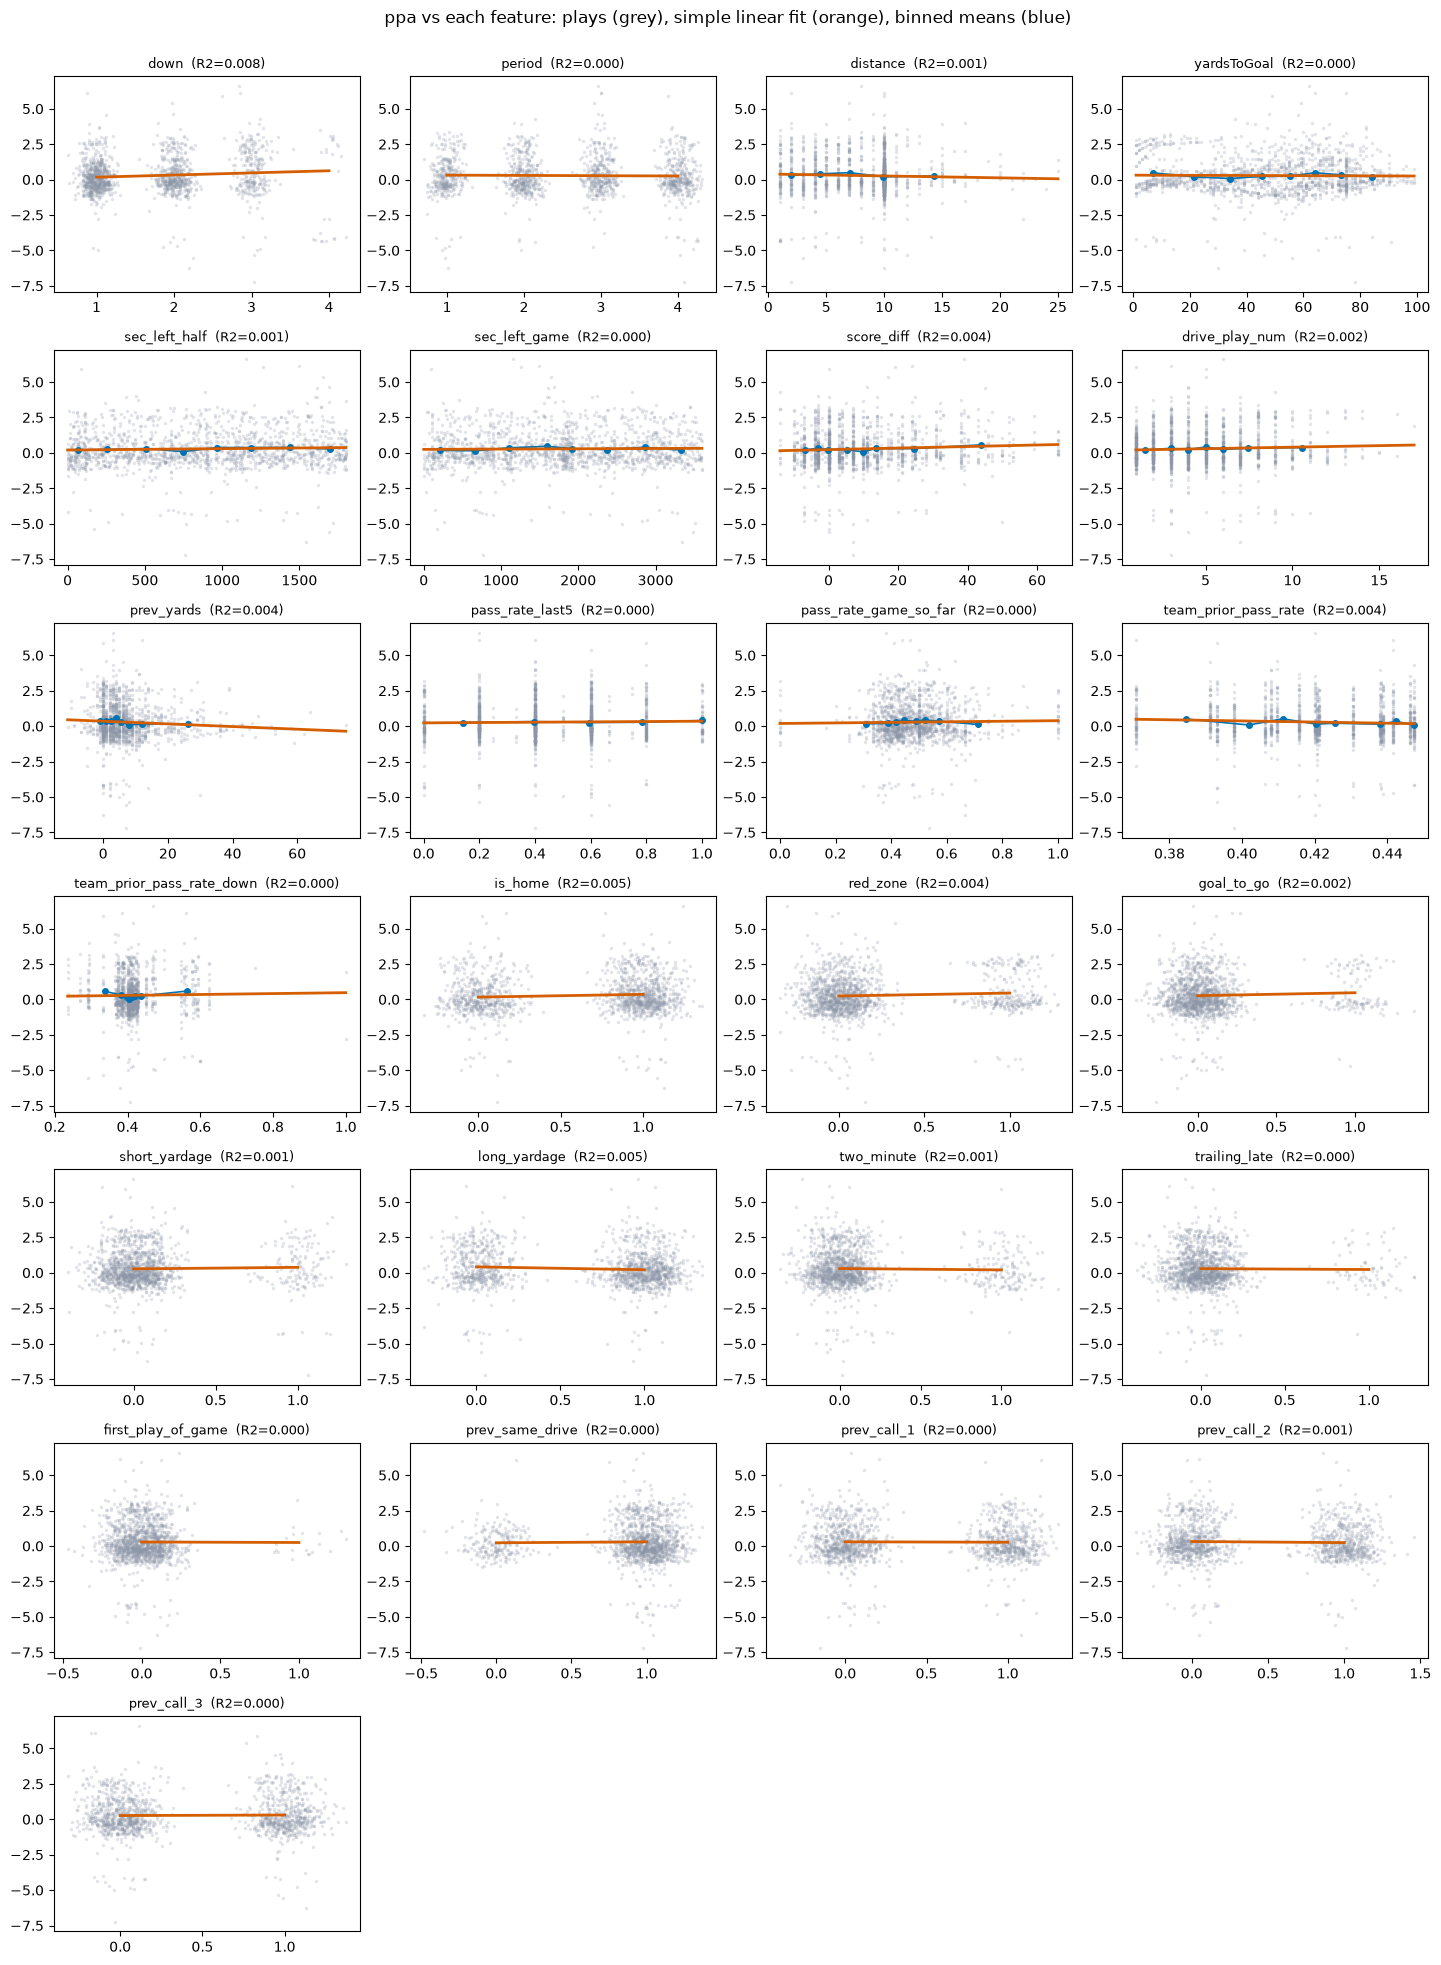

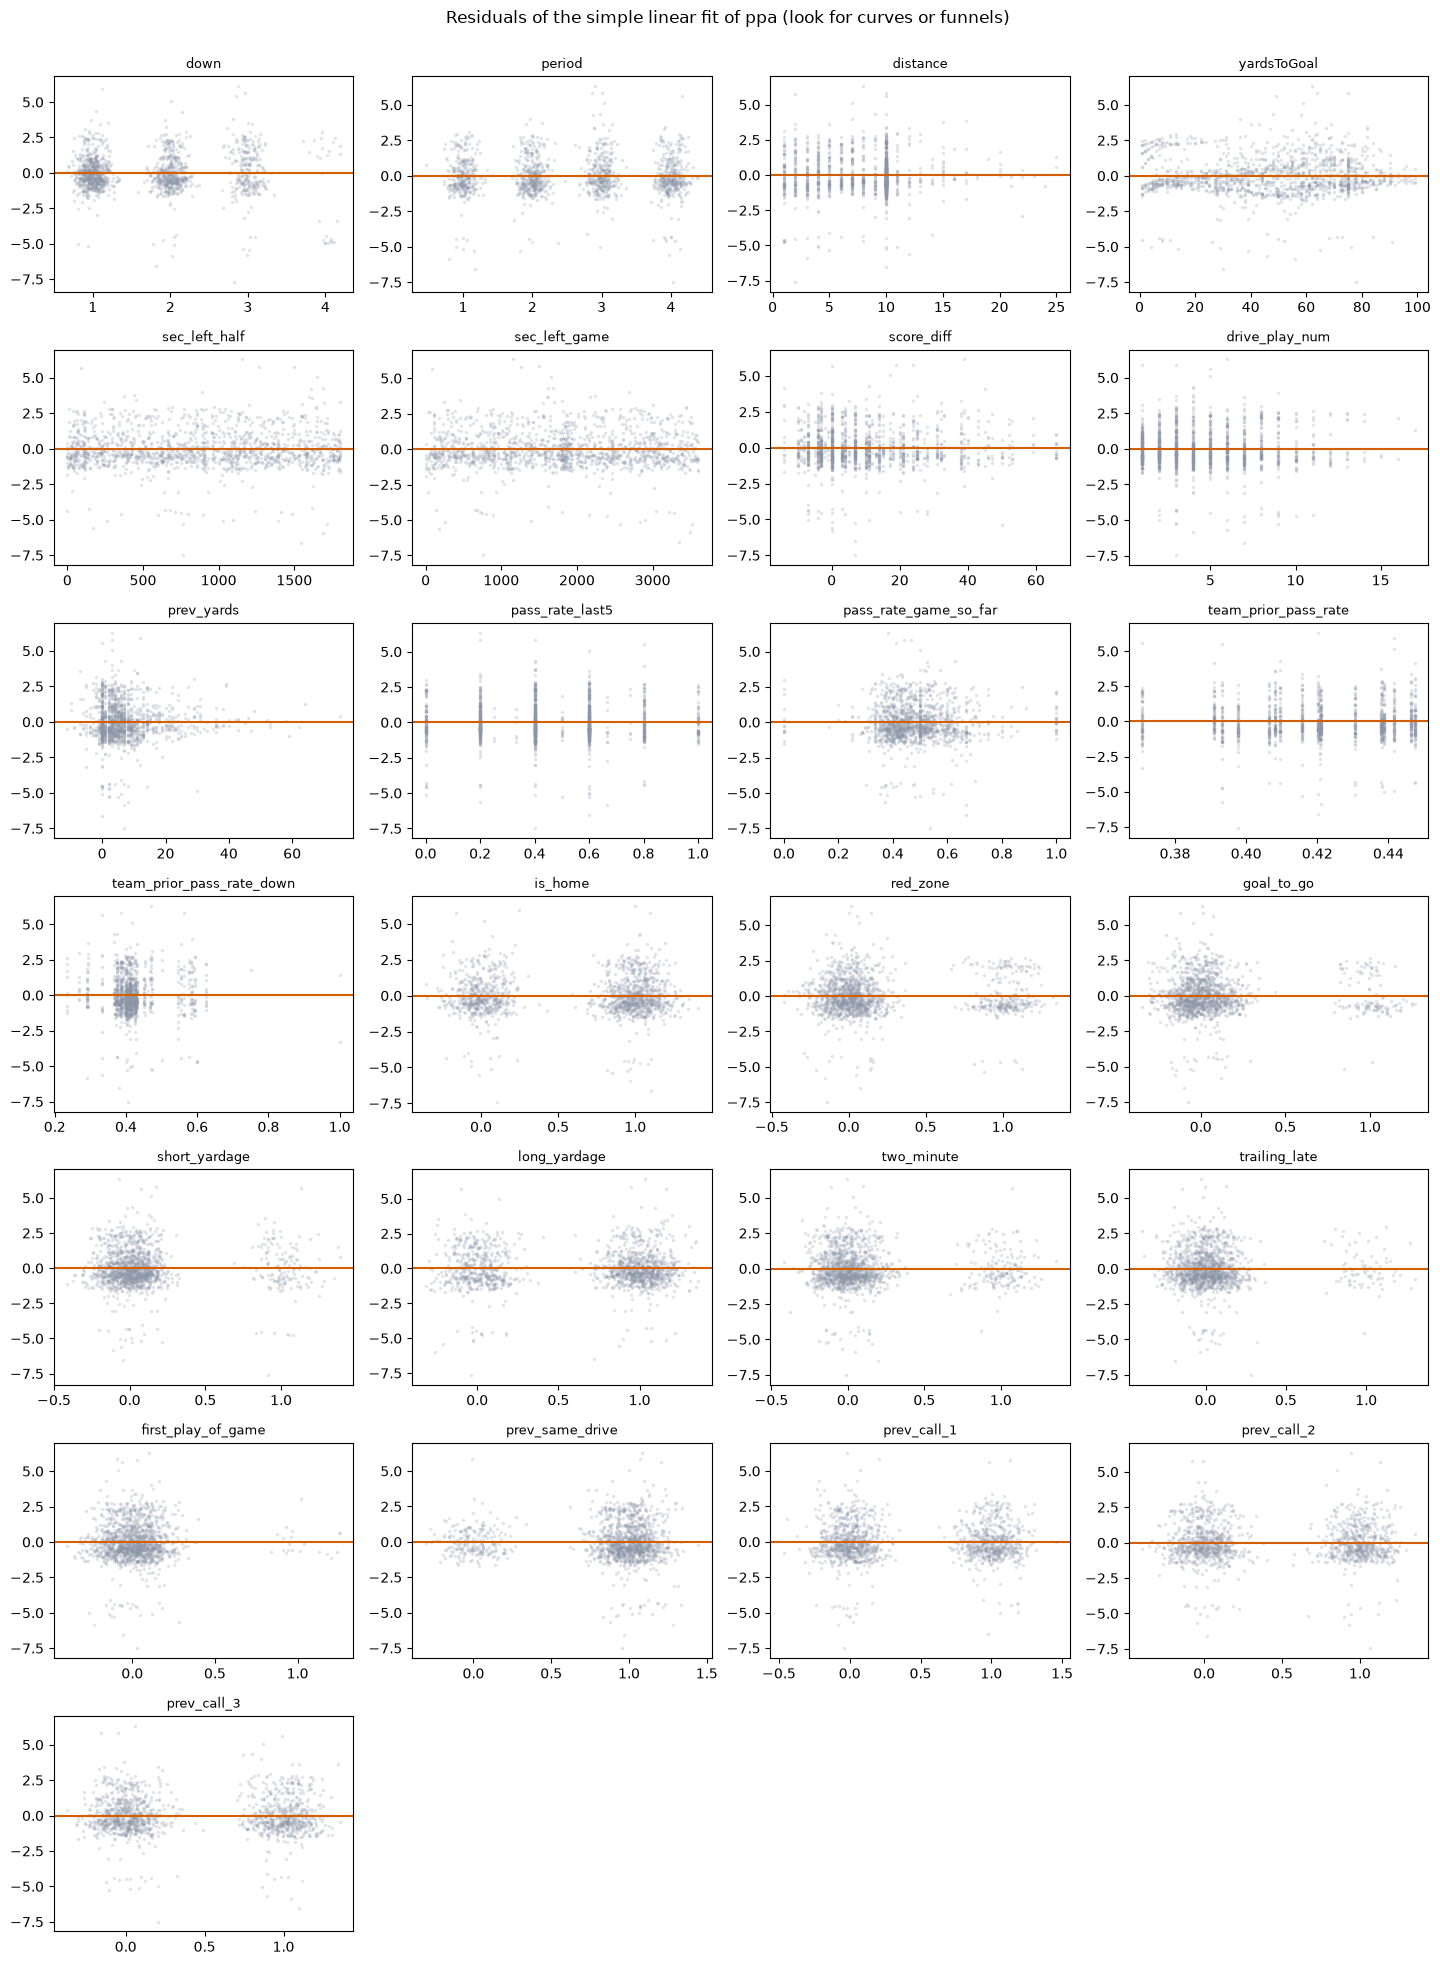

In [16]:
rng = np.random.default_rng(0)
usable_reg = [f for f in feature_cols if f in simple_reg.index]

# Scatter + fitted line
fig, axes = make_grid(len(usable_reg))
for ax, f in zip(axes, usable_reg):
    d = reg[[f, REG_TARGET]].dropna()
    x, y = d[f].to_numpy(float), d[REG_TARGET].to_numpy(float)
    jitter = 0.12 * rng.standard_normal(len(x)) if d[f].nunique() <= 6 else 0
    ax.scatter(x + jitter, y, s=6, alpha=0.25, color=NEUTRAL, linewidths=0)
    if d[f].nunique() > 6:
        bm = d.groupby(pd.qcut(d[f], 8, duplicates="drop"), observed=True).agg(x=(f, "mean"), y=(REG_TARGET, "mean"))
        ax.plot(bm["x"], bm["y"], "o-", color=CLASS_COLORS["Pass"], ms=4, lw=1.2)
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, simple_reg.loc[f, "b0"] + simple_reg.loc[f, "b1"] * xs, color=TEAM_COLORS["Georgia"], lw=2)
    ax.set_title(f"{f}  (R2={simple_reg.loc[f, 'R2']:.3f})", fontsize=9)
fig.suptitle(f"{REG_TARGET} vs each feature: plays (grey), simple linear fit (orange), binned means (blue)", y=1.0)
fig.tight_layout(); savefig(fig, "06_scatter_simple_regression"); plt.show()

# Residual plots
fig, axes = make_grid(len(usable_reg))
for ax, f in zip(axes, usable_reg):
    d = reg[[f, REG_TARGET]].dropna()
    x, y = d[f].to_numpy(float), d[REG_TARGET].to_numpy(float)
    resid = y - (simple_reg.loc[f, "b0"] + simple_reg.loc[f, "b1"] * x)
    jitter = 0.12 * rng.standard_normal(len(x)) if d[f].nunique() <= 6 else 0
    ax.scatter(x + jitter, resid, s=6, alpha=0.25, color=NEUTRAL, linewidths=0)
    ax.axhline(0, color=TEAM_COLORS["Georgia"], lw=1.5)
    ax.set_title(f, fontsize=9)
fig.suptitle(f"Residuals of the simple linear fit of {REG_TARGET} (look for curves or funnels)", y=1.0)
fig.tight_layout(); savefig(fig, "06_residuals_simple_regression"); plt.show()

## Correlation matrix and redundant features

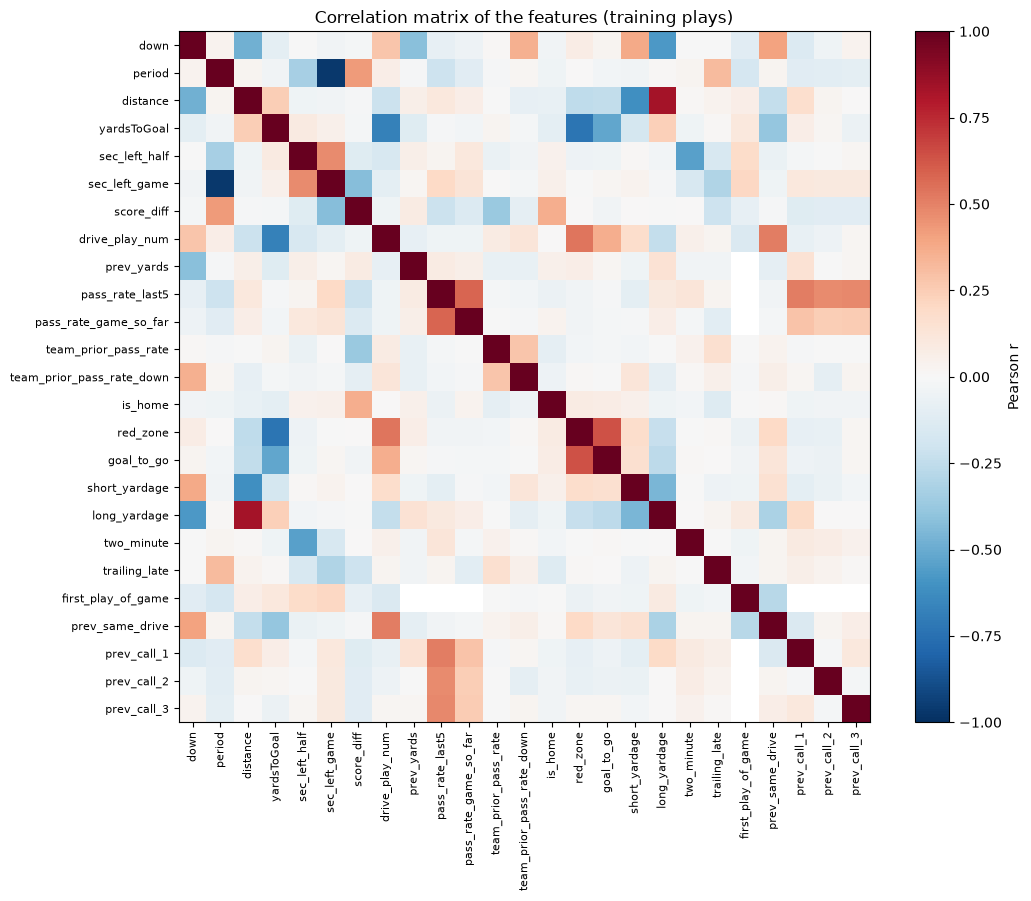

Feature pairs with |r| >= 0.6:


,feature_a,feature_b,r,abs_r
0,period,sec_left_game,-0.963,0.963
1,distance,long_yardage,0.833,0.833
2,yardsToGoal,red_zone,-0.729,0.729
3,yardsToGoal,drive_play_num,-0.679,0.679
4,red_zone,goal_to_go,0.639,0.639
5,distance,short_yardage,-0.613,0.613


In [17]:
usable = [f for f in feature_cols if f not in zero_var and f not in high_missing]
C = eda[usable].corr()

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(C.values, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(usable))); ax.set_xticklabels(usable, rotation=90, fontsize=8)
ax.set_yticks(range(len(usable))); ax.set_yticklabels(usable, fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("Correlation matrix of the features (training plays)")
fig.tight_layout(); savefig(fig, "07_correlation_matrix"); plt.show()

# Pairs worth knowing about (|r| >= 0.6), strongest first
iu = np.triu_indices(len(usable), k=1)
pairs = pd.DataFrame({"feature_a": np.array(usable)[iu[0]], "feature_b": np.array(usable)[iu[1]], "r": C.values[iu]})
pairs["abs_r"] = pairs["r"].abs()
pairs = pairs[pairs["abs_r"] >= 0.6].sort_values("abs_r", ascending=False).reset_index(drop=True)
print("Feature pairs with |r| >= 0.6:")
display(pairs.round(3))
pairs.round(3).to_csv(table_dir / "07_correlated_pairs.csv", index=False)

In [18]:
# Greedy removal of redundant features
target_assoc = eda[usable].corrwith(eda["is_pass"]).abs().fillna(0)
work = C.abs().copy()
keep = list(usable)
dropped_corr = []

while True:
    arr = work.loc[keep, keep].to_numpy(copy=True)
    np.fill_diagonal(arr, 0)
    arr = np.nan_to_num(arr)
    i, j = np.unravel_index(arr.argmax(), arr.shape)
    r = arr[i, j]
    if r < CORR_THRESHOLD:
        break
    a, b = keep[i], keep[j]
    if a in MANUAL_KEEP and b in MANUAL_KEEP:
        work.loc[a, b] = work.loc[b, a] = 0
        continue
    if a in MANUAL_KEEP:
        drop, other, rule = b, a, "other feature is protected"
    elif b in MANUAL_KEEP:
        drop, other, rule = a, b, "other feature is protected"
    elif (a in PREFER_DROP) != (b in PREFER_DROP):
        drop, other = (a, b) if a in PREFER_DROP else (b, a)
        rule = "engineered / derived feature"
    else:
        drop, other = (a, b) if target_assoc[a] < target_assoc[b] else (b, a)
        rule = "weaker link to pass/run"
    dropped_corr.append(dict(dropped=drop, kept_instead=other, abs_r=round(float(r), 3), rule=rule,
                             assoc_with_pass_dropped=round(float(target_assoc[drop]), 3),
                             assoc_with_pass_kept=round(float(target_assoc[other]), 3)))
    keep.remove(drop)

dropped_df = pd.DataFrame(dropped_corr)
if dropped_df.empty:
    print(f"No pair of features has |r| >= {CORR_THRESHOLD}; nothing dropped.")
else:
    print(f"Dropped for redundancy (|r| >= {CORR_THRESHOLD}):")
    display(dropped_df)
    dropped_df.to_csv(table_dir / "07_dropped_for_correlation.csv", index=False)
print(f"\n{len(keep)} features kept out of {len(feature_cols)}")

Dropped for redundancy (|r| >= 0.8):


,dropped,kept_instead,abs_r,rule,assoc_with_pass_dropped,assoc_with_pass_kept
0,sec_left_game,period,0.963,engineered / derived feature,0.111,0.121
1,long_yardage,distance,0.833,engineered / derived feature,0.065,0.105



23 features kept out of 25


## Blowout scenarios

In [19]:
blowout = ((eda["score_diff"].abs() >= 28) & (eda["period"] >= 3)).rename("blowout (|lead| >= 28, 2nd half)")
print(eda.groupby(blowout)["is_pass"].agg(pass_rate="mean", plays="size").round(3))
print("\nPlays where the offense trails (score_diff < 0):", int((eda["score_diff"] < 0).sum()),
      f"({(eda['score_diff'] < 0).mean():.1%} of training plays) - few trailing plays means little data on comeback situations")

                                  pass_rate  plays
blowout (|lead| >= 28, 2nd half)                  
False                                 0.448   1213
True                                  0.313    182

Plays where the offense trails (score_diff < 0): 363 (26.0% of training plays) - few trailing plays means little data on comeback situations


## Save the decisions

In [20]:
decisions = {
    "settings": {"CORR_THRESHOLD": CORR_THRESHOLD, "MAX_MISSING": MAX_MISSING,
                 "MANUAL_KEEP": MANUAL_KEEP, "PREFER_DROP": PREFER_DROP,
                 "REG_TARGET": REG_TARGET, "eda_split": "train"},
    "dropped": {
        "zero_variance": zero_var,
        "high_missing": high_missing,
        "correlated": dropped_corr,
    },
    "categorical": [f for f in cat_f if f in keep],
    "numeric": [f for f in num_f if f in keep],
    "binary": [f for f in bin_f if f in keep],
    "targets": fl["targets"],
    "optional_categorical": fl.get("optional_categorical", []),
    "group_column": fl["group_column"],
    "split_column": fl["split_column"],
}
with open(processed_dir / "feature_lists_after_eda.json", "w") as f:
    json.dump(decisions, f, indent=2)

n_kept = len(decisions["categorical"]) + len(decisions["numeric"]) + len(decisions["binary"])
print(f"Saved {processed_dir / 'feature_lists_after_eda.json'}  ({n_kept} features kept)")
print("Figures:", len(list(fig_dir.glob('*.png'))), "in", fig_dir)
print("Tables: ", len(list(table_dir.glob('*.csv'))), "in", table_dir)

Saved /Users/wrennicol/Documents/GitHub/college-football-play-prediction/data/processed/feature_lists_after_eda.json  (23 features kept)
Figures: 10 in /Users/wrennicol/Documents/GitHub/college-football-play-prediction/reports/figures
Tables:  7 in /Users/wrennicol/Documents/GitHub/college-football-play-prediction/reports/tables
